# РК 1. Разведочный анализ данных об SQL-инъекциях
Данные получены пятью GET-запросами через `client.py` и объединены по `id` (inner join). Пропуски сохраняются; для частот они исключаются, а для длин текстов не заменяются пустыми строками.

In [1]:
import re
from collections import Counter
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
df = pd.read_csv("sql_injections_merged.csv")
original_columns = df.columns.tolist()

def bar(counts, title):
    if counts.empty:
        print("Нет данных для графика:", title)
        return
    counts.sort_values().plot.barh(figsize=(10, 6), title=title)
    plt.xlabel("Количество")
    plt.tight_layout()
    plt.show()

def split_counts(column, pattern, lower=False):
    tokens = []
    for value in df[column].dropna():
        for token in re.split(pattern, value):
            token = token.strip()
            if lower:
                token = token.lower()
            if token:
                tokens.append(token)
    return pd.Series(Counter(tokens), dtype="int64").sort_values(ascending=False)

def leaders(counts, k=3):
    return "; ".join(f"{name}: {count}" for name, count in counts.head(k).items()) or "нет значений"

def conclusion(text):
    display(Markdown("**Вывод.** " + text))


## 1. Общая информация

Размер: (14133, 15)


,dtype
id,int64
Title,str
Category,str
Attack Type,str
Scenario Description,str
Attack Steps,str
Tools Used,str
Target Type,str
Vulnerability,str
MITRE Technique,str


,Пропуски,"Доля, %"
id,0,0.00
Title,0,0.00
Category,0,0.00
Attack Type,0,0.00
Scenario Description,0,0.00
Attack Steps,0,0.00
Tools Used,14,0.10
Target Type,4,0.03
Vulnerability,18,0.13
MITRE Technique,24,0.17


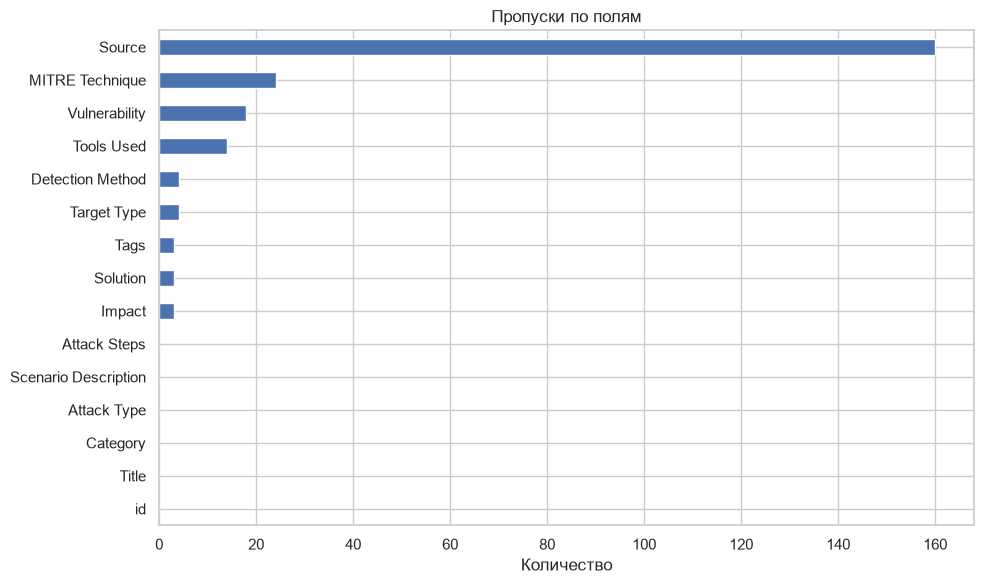

**Вывод.** Пропущено 0.11% ячеек; больше всего пропусков: Source: 160; MITRE Technique: 24; Vulnerability: 18. Полных дубликатов — 0, повторов id — 0; пропуски уменьшают число наблюдений в анализе отдельных полей.

In [2]:
print("Размер:", df.shape)
display(df.dtypes.to_frame("dtype"))
missing = pd.DataFrame({"Пропуски": df.isna().sum(), "Доля, %": df.isna().mean().mul(100).round(2)})
display(missing)
bar(missing["Пропуски"], "Пропуски по полям")
duplicates = int(df.duplicated().sum())
missing_share = df.isna().to_numpy().mean() * 100
conclusion(f"Пропущено {missing_share:.2f}% ячеек; больше всего пропусков: {leaders(missing['Пропуски'].sort_values(ascending=False))}. Полных дубликатов — {duplicates}, повторов id — {df['id'].duplicated().sum()}; пропуски уменьшают число наблюдений в анализе отдельных полей.")

## 2. Категории

,Количество,"Доля, %"
Category,,
Insider Threat,569,4.026038
Physical / Hardware Attacks,548,3.877450
Quantum Cryptography & Post-Quantum Threats,542,3.834996
Wireless Attacks (Advanced),535,3.785467
Malware & Threat,528,3.735937
Satellite & Space Infrastructure Security,515,3.643954
DFIR,510,3.608576
Blockchain / Web3,503,3.559046
Red Team,503,3.559046


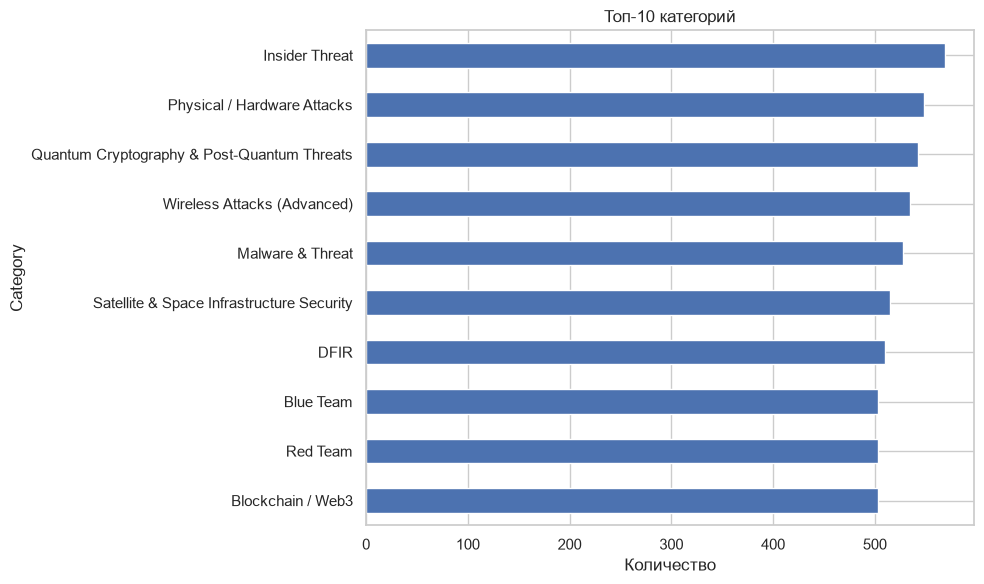

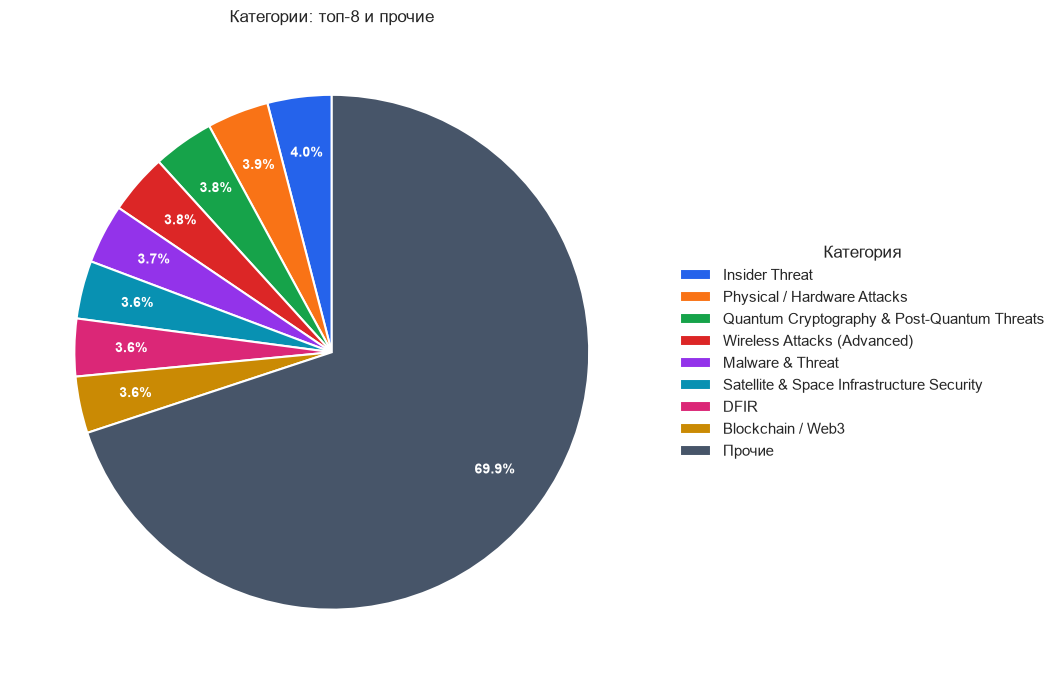

**Вывод.** Ведущие категории: Insider Threat: 569; Physical / Hardware Attacks: 548; Quantum Cryptography & Post-Quantum Threats: 542. Доля крупнейшей среди заполненных записей — 4.0%; сравнение долей показывает степень концентрации распределения.

In [3]:
categories = df["Category"].value_counts()
display(pd.DataFrame({"Количество": categories, "Доля, %": categories / categories.sum() * 100}).head(10))
bar(categories.head(10), "Топ-10 категорий")
pie = categories.head(8).copy()
if len(categories) > 8:
    pie.loc["Прочие"] = categories.iloc[8:].sum()
if not pie.empty:
    colors = ["#2563EB", "#F97316", "#16A34A", "#DC2626", "#9333EA",
              "#0891B2", "#DB2777", "#CA8A04", "#475569"]
    fig, ax = plt.subplots(figsize=(12, 7))
    wedges, _, percentages = ax.pie(
        pie.values, colors=colors[:len(pie)], autopct="%1.1f%%",
        startangle=90, pctdistance=0.78,
        wedgeprops={"edgecolor": "white", "linewidth": 1.5},
        textprops={"color": "white", "weight": "bold", "fontsize": 10},
    )
    ax.legend(wedges, pie.index, title="Категория", loc="center left",
              bbox_to_anchor=(1.02, 0.5), frameon=False)
    ax.set_title("Категории: топ-8 и прочие")
    ax.set_aspect("equal")
    plt.tight_layout()
    plt.show()
conclusion(f"Ведущие категории: {leaders(categories)}. Доля крупнейшей среди заполненных записей — {categories.iloc[0] / categories.sum():.1%}; сравнение долей показывает степень концентрации распределения.")

Распределение категорий достаточно широкое: крупнейшая занимает лишь 4,0% заполненных записей, поэтому одной резко доминирующей категории нет. Лидирующие категории описывают угрозы шире SQL-инъекций.

## 3. Типы атак

Attack Type
Hardware Interface Exploitation    161
Wireless Attacks (Advanced)         95
Dependency Confusion                91
Fuzzer Configuration                75
Malicious Libraries                 74
Malicious Library                   71
Privilege Escalation                61
Misuse of Legitimate Tools          55
Removable Media Attack              55
Data Exfiltration                   52
Name: count, dtype: int64

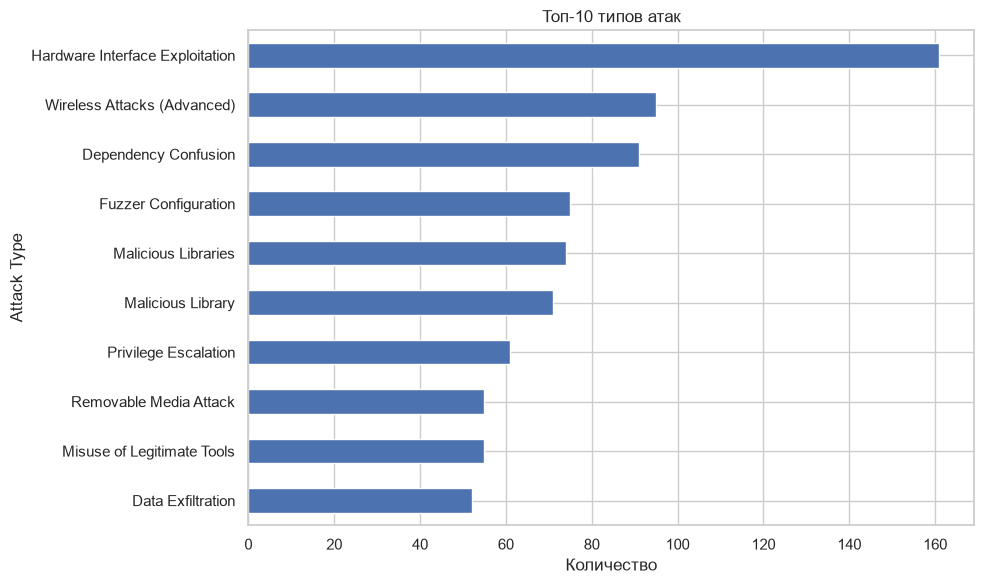

**Вывод.** Лидируют Hardware Interface Exploitation: 161; Wireless Attacks (Advanced): 95; Dependency Confusion: 91; однако топ-10 охватывает лишь 5.6% заполненных строк. Всего выделено 8834 типов, из них 7974 (90.3%) встречаются по одному разу, что указывает на высокую детализацию названий и затрудняет сравнение редких типов.

In [4]:
attacks = df["Attack Type"].value_counts()
display(attacks.head(10))
bar(attacks.head(10), "Топ-10 типов атак")
singletons = int((attacks == 1).sum())
conclusion(f"Лидируют {leaders(attacks)}; однако топ-10 охватывает лишь {attacks.head(10).sum() / attacks.sum():.1%} заполненных строк. Всего выделено {len(attacks)} типов, из них {singletons} ({singletons / len(attacks):.1%}) встречаются по одному разу, что указывает на высокую детализацию названий и затрудняет сравнение редких типов.")

## 4. Tools Used

Burp Suite        1117
Wireshark          711
Python             507
curl               486
Postman            289
PowerShell         265
bash               251
Scapy              234
Browser            196
PyTorch            190
Ghidra             184
AFL++              182
GitHub             180
Hardhat            177
Android Studio     166
dtype: int64

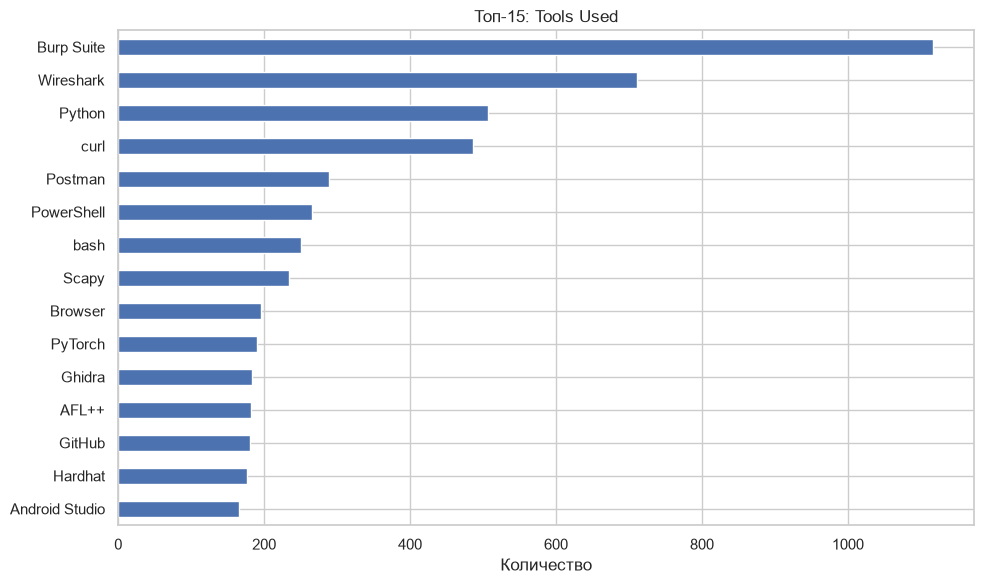

**Вывод.** Чаще всего указаны Burp Suite: 1117; Wireshark: 711; Python: 507. Частота названий характеризует упоминаемый стек атакующего, но не доказывает фактическое использование инструмента.

In [5]:
tools = split_counts('Tools Used', '[,;#]', lower=False)
display(tools.head(15))
bar(tools.head(15), "Топ-15: Tools Used")
conclusion(f"Чаще всего указаны {leaders(tools)}. Частота названий характеризует упоминаемый стек атакующего, но не доказывает фактическое использование инструмента.")

Burp Suite указывает на тестирование веб-приложений, Wireshark — на анализ сетевого трафика, Python — на автоматизацию. В этом пункте регистр сохранён согласно заданию, поэтому варианты написания названий считаются отдельно.

## 5. MITRE Technique

T1203        740
T1499        401
T1606        352
T1552.001    302
T1557        280
T1040        280
T1609        271
T1600        259
T1059        239
T1204.002    235
dtype: int64

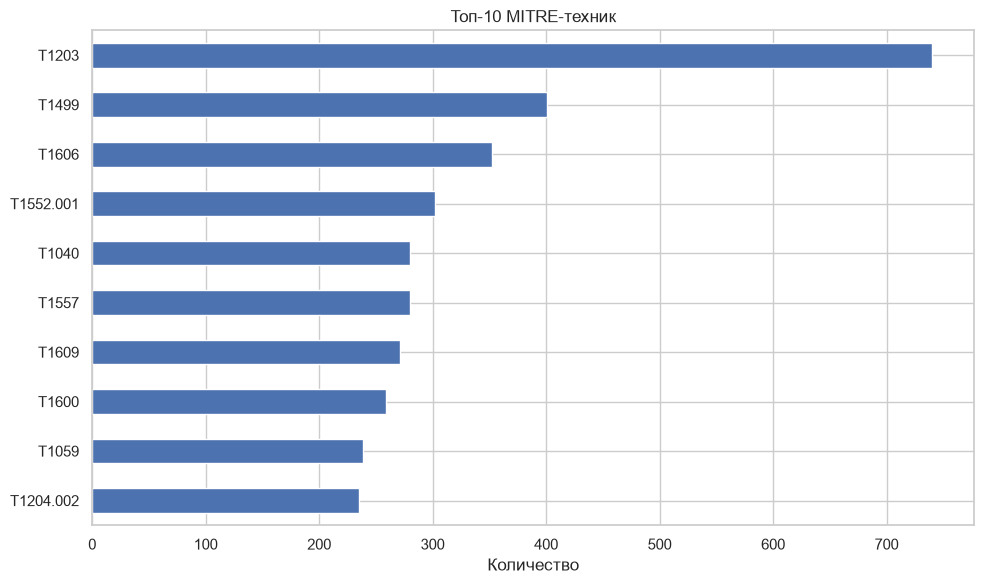

**Вывод.** Наиболее частые идентификаторы: T1203: 740; T1499: 401; T1606: 352. Соответствие SQL-инъекциям нужно оценивать по описаниям атак: само наличие идентификатора не подтверждает правильность разметки.

In [6]:
mitre = pd.Series(Counter(t for value in df["MITRE Technique"].dropna() for t in re.findall(r"T\d{4}(?:\.\d{3})?", value)), dtype="int64").sort_values(ascending=False)
display(mitre.head(10))
bar(mitre.head(10), "Топ-10 MITRE-техник")
conclusion(f"Наиболее частые идентификаторы: {leaders(mitre)}. Соответствие SQL-инъекциям нужно оценивать по описаниям атак: само наличие идентификатора не подтверждает правильность разметки.")

Топ-3 техники дают только 9,8% упоминаний: они не покрывают большинство разметки. Нельзя переносить долю упоминаний на долю атак, поскольку одна запись может содержать несколько техник.

## 6. Tags

redteam             271
phishing            202
mitm                185
persistence         178
android             139
dos                 127
fuzzing             118
firmware            110
rce                 109
npm                 109
ble                 105
spoofing            102
prompt injection    102
zigbee              101
replay               98
powershell           95
sdr                  95
ethicalhacking       91
qkd                  90
ssrf                 86
dtype: int64

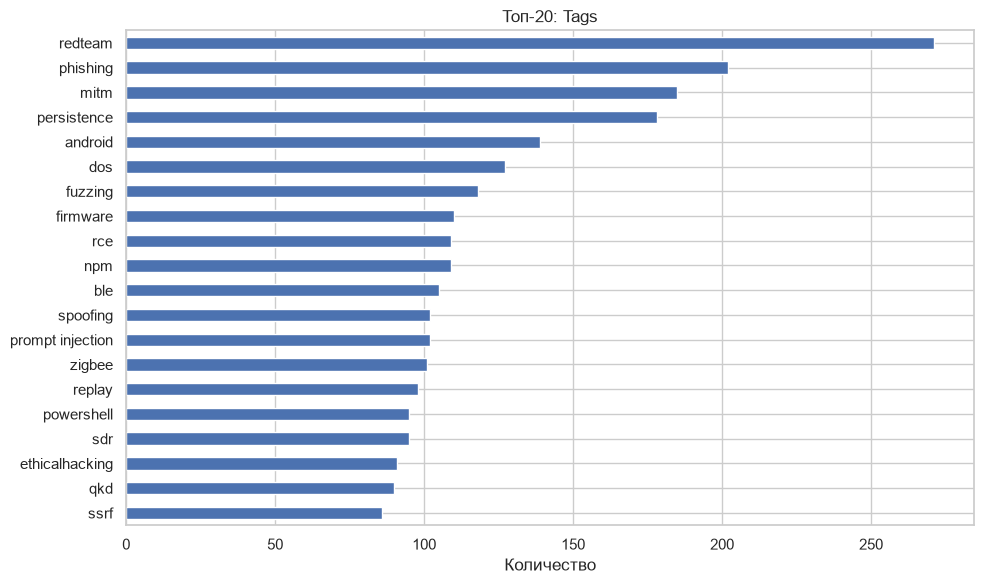

**Вывод.** Чаще всего указаны redteam: 271; phishing: 202; mitm: 185. Теги характеризуют тематику записей; наличие redteam, phishing или mitm указывает на контекст, выходящий за пределы одних SQL-инъекций.

In [7]:
tags = split_counts('Tags', '[,;#]', lower=True)
display(tags.head(20))
bar(tags.head(20), "Топ-20: Tags")
conclusion(f"Чаще всего указаны {leaders(tags)}. Теги характеризуют тематику записей; наличие redteam, phishing или mitm указывает на контекст, выходящий за пределы одних SQL-инъекций.")

## 7. Source

Simulated                   2347
OWASP                       1783
MITRE                       1225
MITRE ATT&CK                 738
https://attack.mitre.org     259
Educational                  251
Educational Simulation       219
HackTricks                   194
SANS                         163
OpenAI                       114
HackerOne                    102
Real-world                    89
GTFOBins                      85
LangChain                     84
PortSwigger                   84
dtype: int64

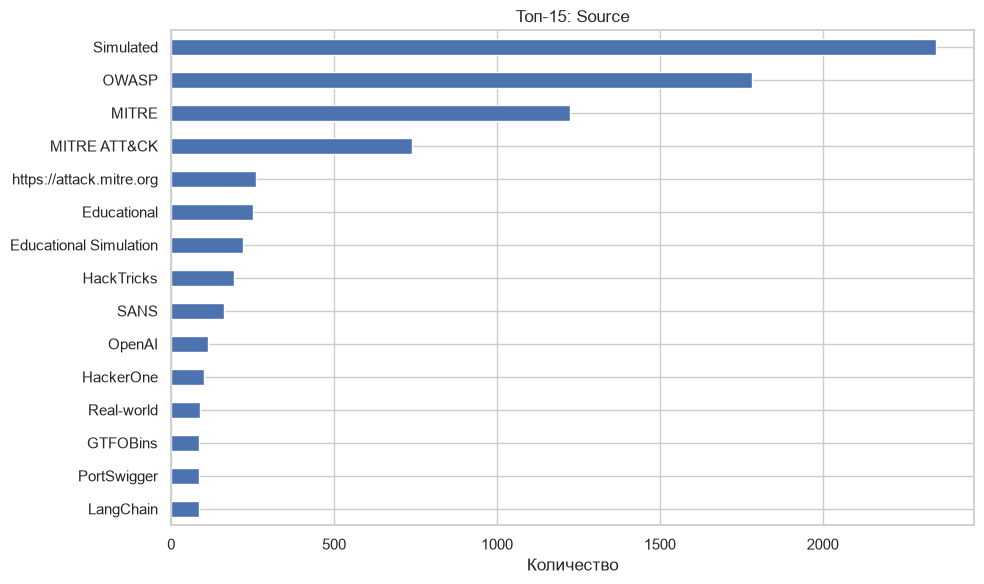

**Вывод.** Чаще всего указаны Simulated: 2347; OWASP: 1783; MITRE: 1225. Частота ссылок не доказывает авторитетность: её нужно оценивать по авторству, первичности публикации и проверяемости материала.

In [8]:
sources = split_counts('Source', '[,;]', lower=False)
display(sources.head(15))
bar(sources.head(15), "Топ-15: Source")
conclusion(f"Чаще всего указаны {leaders(sources)}. Частота ссылок не доказывает авторитетность: её нужно оценивать по авторству, первичности публикации и проверяемости материала.")

OWASP и MITRE — профильные источники, но их названия в поле Source сами по себе не подтверждают происхождение конкретной записи. Метка Simulated встречается 2347 раз и обозначает симулированные данные, что ограничивает выводы о реальных атаках.

## 8. Category × Attack Type

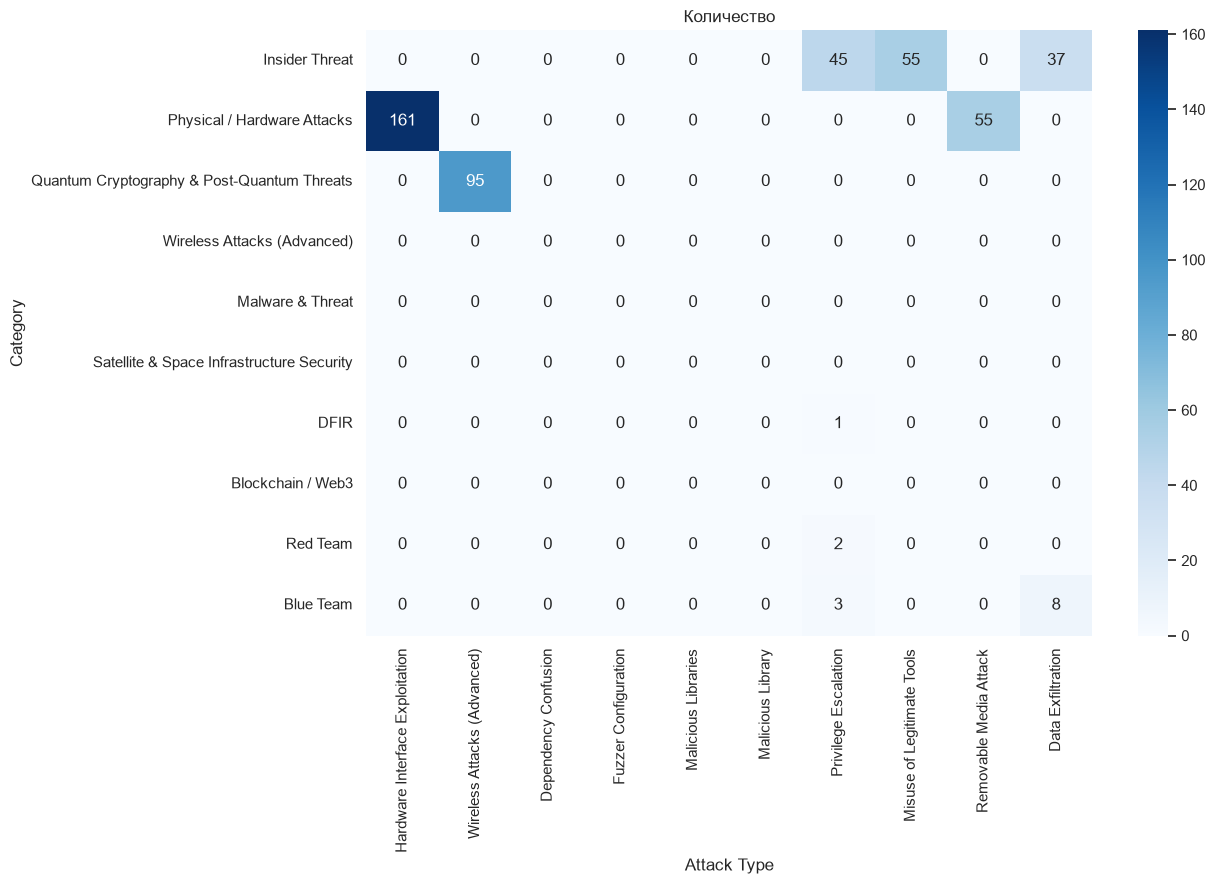

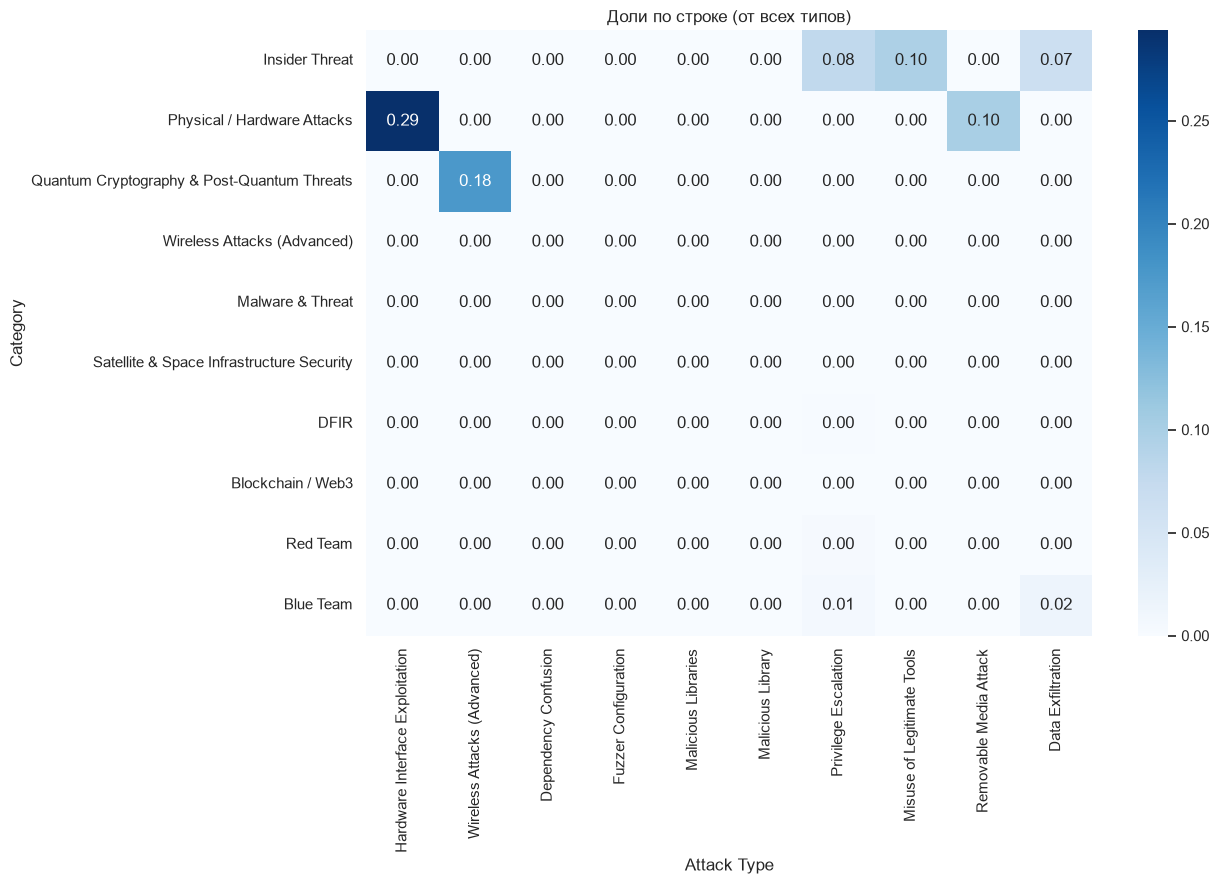

**Вывод.** Самая частая пара в показанном срезе: Physical / Hardware Attacks → Hardware Interface Exploitation (161 записей). Доля этого типа среди всех заполненных типов данной категории — 29.4%; связь согласуется с тематикой аппаратных атак, но не устанавливает причинность.

In [9]:
pairs = pd.crosstab(df["Category"], df["Attack Type"])
selected = pairs.reindex(index=categories.head(10).index, columns=attacks.head(10).index, fill_value=0)
# Знаменатель включает все типы атак категории, а не только показанный топ-10.
shares = selected.div(pairs.sum(axis=1).reindex(selected.index).replace(0, float("nan")), axis=0)
for table, title, fmt in [(selected, "Количество", "d"), (shares, "Доли по строке (от всех типов)", ".2f")]:
    plt.figure(figsize=(13, 9))
    sns.heatmap(table, annot=True, fmt=fmt, cmap="Blues")
    plt.title(title); plt.tight_layout(); plt.show()
best_pair = selected.stack().idxmax()
conclusion(f"Самая частая пара в показанном срезе: {best_pair[0]} → {best_pair[1]} ({selected.loc[best_pair]} записей). Доля этого типа среди всех заполненных типов данной категории — {shares.loc[best_pair]:.1%}; связь согласуется с тематикой аппаратных атак, но не устанавливает причинность.")

Связь Physical / Hardware Attacks → Hardware Interface Exploitation выражена и согласуется с названиями категории и типа. Для остальных пар силу связи следует оценивать по долям, а не только по абсолютным числам.

## 9. Attack Type × MITRE

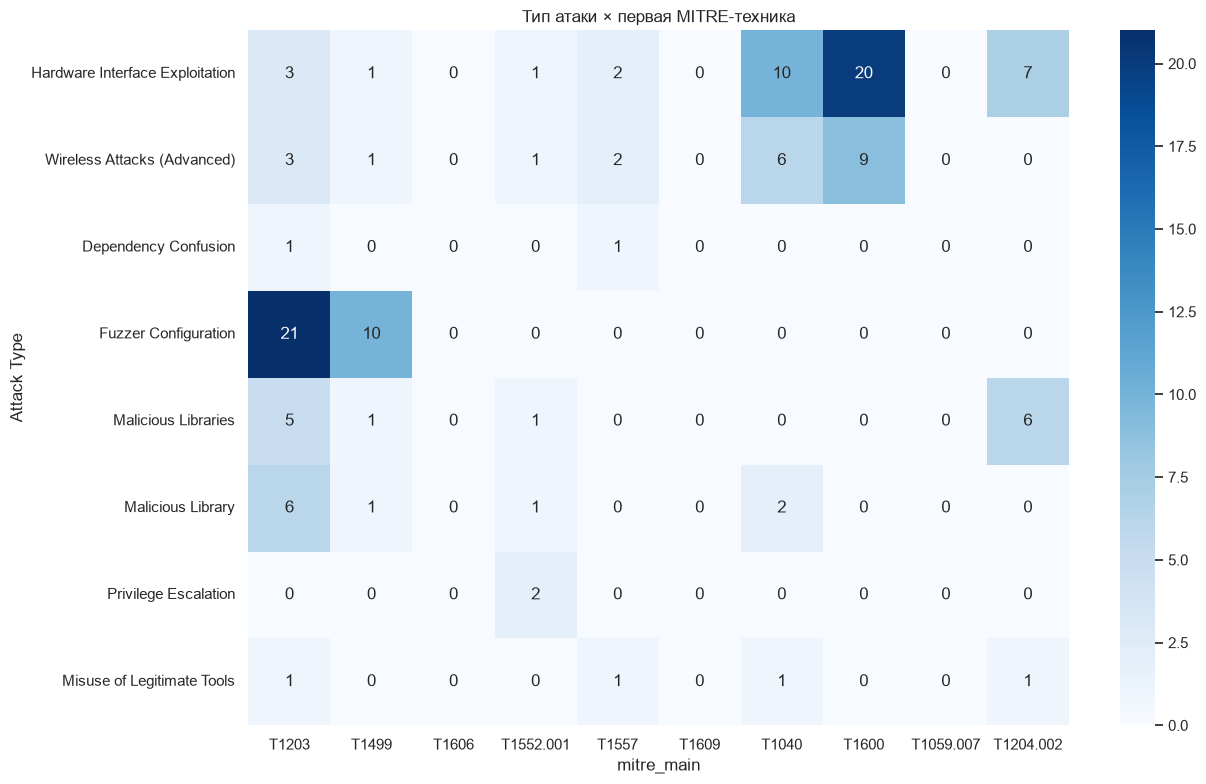

**Вывод.** В показанном срезе самая частая связь — Fuzzer Configuration → T1203 (21 записей). Матрица показывает распределение первой техники по типам атак; нулевые ячейки означают отсутствие такой пары в выбранном срезе, а дополнительные техники не учитываются.

In [10]:
df["mitre_main"] = df["MITRE Technique"].str.extract(r"(T\d{4}(?:\.\d{3})?)", expand=False)
main_counts = df["mitre_main"].value_counts()
attack_mitre = pd.crosstab(df["Attack Type"], df["mitre_main"])
selected_mitre = attack_mitre.reindex(index=attacks.head(8).index, columns=main_counts.head(10).index, fill_value=0)
plt.figure(figsize=(13, 8))
sns.heatmap(selected_mitre, annot=True, fmt="d", cmap="Blues")
plt.title("Тип атаки × первая MITRE-техника"); plt.tight_layout(); plt.show()
best_mitre = selected_mitre.stack().idxmax()
conclusion(f"В показанном срезе самая частая связь — {best_mitre[0]} → {best_mitre[1]} ({selected_mitre.loc[best_mitre]} записей). Матрица показывает распределение первой техники по типам атак; нулевые ячейки означают отсутствие такой пары в выбранном срезе, а дополнительные техники не учитываются.")

## 10. Длины текстов

,len_scenario_description,len_attack_steps,len_solution
count,14133.0,14133.0,14130.0
mean,127.6,698.1,63.0
std,90.9,464.7,38.0
min,30.0,23.0,9.0
25%,79.0,387.0,38.0
50%,103.0,554.0,50.0
75%,143.0,890.0,83.0
max,795.0,6003.0,520.0


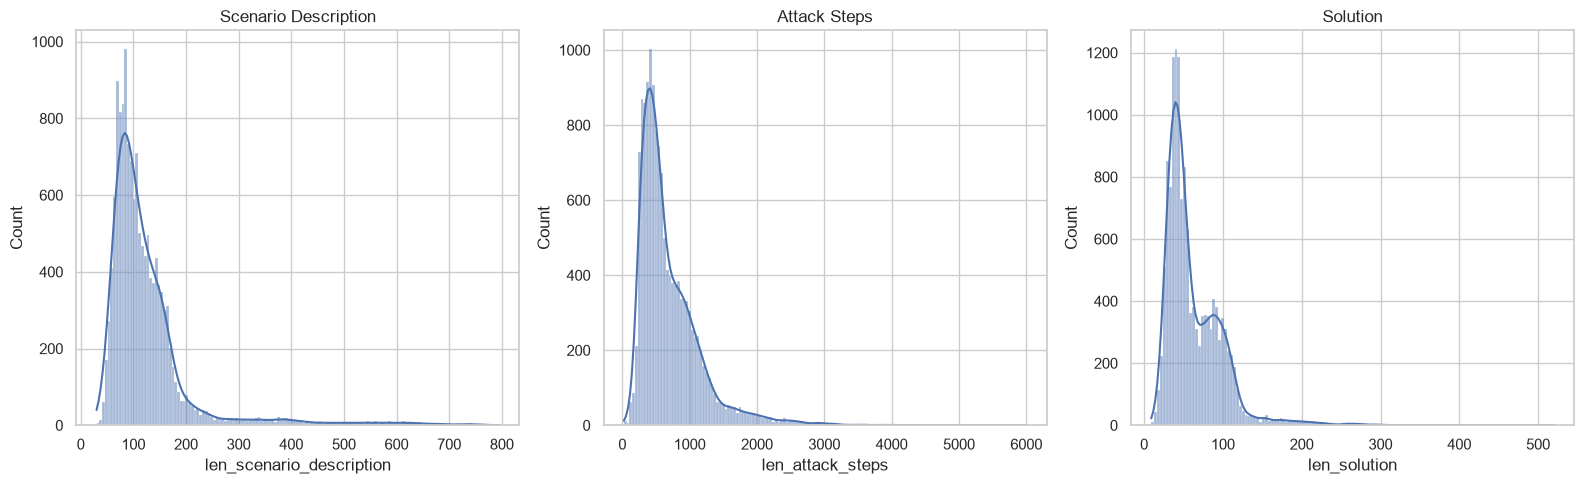

**Вывод.** Наибольшая средняя длина у len_attack_steps: 698.1 символа, медиана — 554.0, максимум — 6003. Верхние выбросы по правилу 1,5 IQR: {'Scenario Description': 891, 'Attack Steps': 652, 'Solution': 396}; они отражают наличие особенно подробных записей и сами по себе не являются ошибками.

In [11]:
text_fields = {"Scenario Description": "len_scenario_description", "Attack Steps": "len_attack_steps", "Solution": "len_solution"}
lengths = pd.DataFrame({name: df[column].str.len() for column, name in text_fields.items()})
display(lengths.describe().round(1))
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
outliers = {}
for ax, (column, name) in zip(axes, text_fields.items()):
    values = lengths[name].dropna()
    sns.histplot(values, kde=True, ax=ax)
    ax.set_title(column)
    q1, q3 = values.quantile([.25, .75])
    outliers[column] = int((values > q3 + 1.5 * (q3 - q1)).sum())
plt.tight_layout(); plt.show()
longest = lengths.mean().idxmax()
conclusion(f"Наибольшая средняя длина у {longest}: {lengths[longest].mean():.1f} символа, медиана — {lengths[longest].median():.1f}, максимум — {lengths[longest].max():.0f}. Верхние выбросы по правилу 1,5 IQR: {outliers}; они отражают наличие особенно подробных записей и сами по себе не являются ошибками.")

## 11. Частые слова в Solution

enforce       1753
disable       1573
block         1298
restrict      1229
access        1011
secure         758
validate       712
avoid          666
input          647
validation     628
monitor        599
apply          562
before         544
add            537
sanitize       533
limit          512
enable         502
strict         424
user           419
via            418
dtype: int64

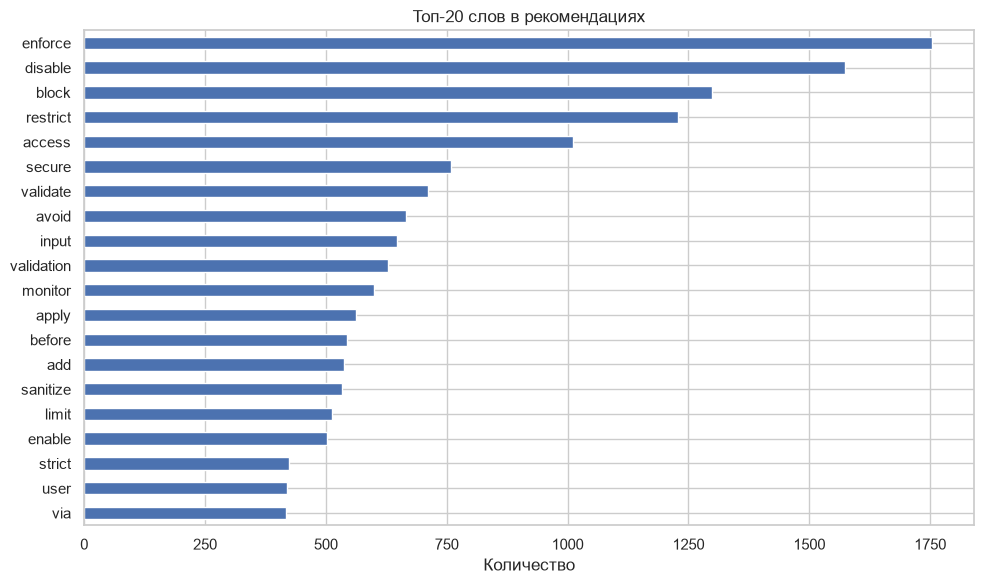

**Вывод.** Чаще встречаются слова: enforce: 1753; disable: 1573; block: 1298; restrict: 1229; access: 1011. Они выделяют темы защиты, но отдельные слова не заменяют чтение рекомендаций и не позволяют точно восстановить целые фразы.

In [12]:
stop_words = set("the a an and or to of in on for with by is are be as at from that this it its can should use using used ensure also all not into through such these their which will have has when where your you they them then than more may must only each any both do does prevent against implement including".split())
words = Counter(word.lower() for value in df["Solution"].dropna()
                for word in re.findall(r"[A-Za-z][A-Za-z\-]+", value)
                if word.lower() not in stop_words)
solution_words = pd.Series(words, dtype="int64").sort_values(ascending=False)
display(solution_words.head(20))
bar(solution_words.head(20), "Топ-20 слов в рекомендациях")
conclusion(f"Чаще встречаются слова: {leaders(solution_words, 5)}. Они выделяют темы защиты, но отдельные слова не заменяют чтение рекомендаций и не позволяют точно восстановить целые фразы.")

Слова enforce, disable, block, restrict и access указывают на ограничение доступа, отключение опасных возможностей и блокировку нежелательных действий. Например, в текстах встречается рекомендация отключать отладочные порты в продуктивной среде.

## 12. Финальная сводка

In [13]:
summary = pd.DataFrame({"dtype": df[original_columns].dtypes.astype(str), "Заполнено": df[original_columns].notna().sum(), "Пропуски": df[original_columns].isna().sum(), "Уникальных": df[original_columns].nunique(dropna=True)})
display(summary)
conclusion(f"В исходных данных {len(df)} строк и {len(original_columns)} полей; число уникальных значений приведено без пропусков. Производные признаки исключены из сводки, чтобы она описывала исходный набор.")

,dtype,Заполнено,Пропуски,Уникальных
id,int64,14133,0,14133
Title,str,14133,0,13793
Category,str,14133,0,64
Attack Type,str,14133,0,8834
Scenario Description,str,14133,0,13866
Attack Steps,str,14133,0,13895
Tools Used,str,14119,14,12935
Target Type,str,14129,4,9885
Vulnerability,str,14115,18,13424
MITRE Technique,str,14109,24,5770


**Вывод.** В исходных данных 14133 строк и 15 полей; число уникальных значений приведено без пропусков. Производные признаки исключены из сводки, чтобы она описывала исходный набор.

## Финальные выводы

In [14]:
conclusion(
    f"1. **Категории и типы атак.** Лидируют {categories.index[0]} ({categories.iloc[0]}) и {attacks.index[0]} ({attacks.iloc[0]}). "
    f"Крупнейшая категория занимает {categories.iloc[0] / categories.sum():.1%}; уникальных типов — {len(attacks)}, большинство встречается один раз."
)
conclusion(
    f"2. **Инструменты.** Чаще упоминаются {leaders(tools)}. "
    "Они отражают веб-тестирование, анализ трафика и автоматизацию."
)
conclusion(
    f"3. **MITRE.** Лидируют {leaders(mitre)}. "
    f"Их доля — {mitre.head(3).sum() / mitre.sum():.1%} упоминаний, поэтому они не покрывают большинство разметки."
)
conclusion(
    f"4. **Теги и источники.** Частые теги: {leaders(tags)}; источники: {leaders(sources)}. "
    "Simulated указывает на моделируемые примеры; авторитетность конкретных записей требует проверки первоисточников."
)
conclusion(
    "5. **Защита.** Основные темы Solution — контроль доступа, блокировка нежелательных действий и отключение опасных возможностей. "
    "Это интерпретация частых слов и примеров текстов, а не подсчёт отдельных защитных мер."
)
conclusion(
    f"6. **Качество.** Пропущено {missing_share:.2f}% ячеек, полных дубликатов — {duplicates}; больше всего пропусков в Source ({df['Source'].isna().sum()}). "
    "Пропуски уменьшают число наблюдений для анализа отдельных полей."
)
conclusion(
    f"7. **Общий итог.** Набор из {len(df)} записей подходит для учебного EDA. "
    "Он охватывает разные кибератаки и моделируемые сценарии, поэтому его репрезентативность именно для реальных SQL-инъекций не доказана."
)

**Вывод.** 1. **Категории и типы атак.** Лидируют Insider Threat (569) и Hardware Interface Exploitation (161). Крупнейшая категория занимает 4.0%; уникальных типов — 8834, большинство встречается один раз.

**Вывод.** 2. **Инструменты.** Чаще упоминаются Burp Suite: 1117; Wireshark: 711; Python: 507. Они отражают веб-тестирование, анализ трафика и автоматизацию.

**Вывод.** 3. **MITRE.** Лидируют T1203: 740; T1499: 401; T1606: 352. Их доля — 9.8% упоминаний, поэтому они не покрывают большинство разметки.

**Вывод.** 4. **Теги и источники.** Частые теги: redteam: 271; phishing: 202; mitm: 185; источники: Simulated: 2347; OWASP: 1783; MITRE: 1225. Simulated указывает на моделируемые примеры; авторитетность конкретных записей требует проверки первоисточников.

**Вывод.** 5. **Защита.** Основные темы Solution — контроль доступа, блокировка нежелательных действий и отключение опасных возможностей. Это интерпретация частых слов и примеров текстов, а не подсчёт отдельных защитных мер.

**Вывод.** 6. **Качество.** Пропущено 0.11% ячеек, полных дубликатов — 0; больше всего пропусков в Source (160). Пропуски уменьшают число наблюдений для анализа отдельных полей.

**Вывод.** 7. **Общий итог.** Набор из 14133 записей подходит для учебного EDA. Он охватывает разные кибератаки и моделируемые сценарии, поэтому его репрезентативность именно для реальных SQL-инъекций не доказана.